# Advanced Statistical Analysis & Hypothesis Testing
### Reproducible inferential statistics using the Wine Recognition dataset

**Objective:** demonstrate normality tests, two-group comparisons, One-Way ANOVA, Two-Way ANOVA, Tukey HSD post-hoc comparisons, confidence intervals, distribution plots, and evidence-based conclusions.

**Dataset:** the Wine Recognition dataset bundled with scikit-learn. It contains chemical measurements from wines grown in the same region in Italy, with three wine cultivars. The notebook uses magnesium as the main outcome for ANOVA and alcohol for a two-group comparison. This is a teaching analysis of an existing dataset, not a claim about a new experiment.

**Decision threshold:** \(\alpha = 0.05\). A p-value below 0.05 is treated as statistically significant. Statistical significance does not by itself establish practical importance or causation.

## 1. Research questions and hypotheses

1. **Normality:** Are the sample distributions consistent with a normal distribution?
   - H₀: the observations are drawn from a normal distribution.
   - H₁: the observations are not drawn from a normal distribution.
2. **Two-group comparison:** Does mean alcohol content differ between cultivar 0 and cultivar 1?
   - H₀: the population means are equal.
   - H₁: the population means differ.
3. **One-Way ANOVA:** Does mean magnesium differ across the three cultivars?
   - H₀: all three population means are equal.
   - H₁: at least one population mean differs.
4. **Two-Way ANOVA:** Are magnesium means associated with cultivar, alcohol group (below/at-or-above the median), or their interaction?
   - H₀ for each term: its effect is zero.
   - H₁: the corresponding main effect or interaction is non-zero.

The normality tests are sensitive to sample size. Interpret them alongside histograms and Q–Q plots, not as automatic pass/fail gates.

## 2. Setup and load the dataset

If needed, install dependencies in your environment with `python -m pip install numpy pandas scipy matplotlib seaborn statsmodels scikit-learn`.

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_wine
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway

ALPHA = 0.05
sns.set_theme(style="whitegrid", context="notebook")

wine = load_wine(as_frame=True)
df = wine.frame.copy()
df = df.rename(columns={"target": "cultivar"})
df["cultivar"] = df["cultivar"].astype("category")
df["cultivar_name"] = df["cultivar"].cat.codes.map(
    {i: name for i, name in enumerate(wine.target_names)}
)

print("Dataset shape:", df.shape)
print("Cultivar counts:")
print(df["cultivar_name"].value_counts())
display(df.head())
display(df.describe().T)

Dataset shape: (178, 15)
Cultivar counts:
cultivar_name
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar,cultivar_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


## 3. Explore distributions

Histograms and Q–Q plots help assess shape, skewness, and outliers. The Shapiro–Wilk test is used on each cultivar's magnesium measurements. The one-sample Kolmogorov–Smirnov test compares standardized observations against a standard normal distribution; because its parameters are estimated from the same sample, its p-value is only an approximate diagnostic here. For a formal normality test with estimated parameters, a Lilliefors correction is preferable.

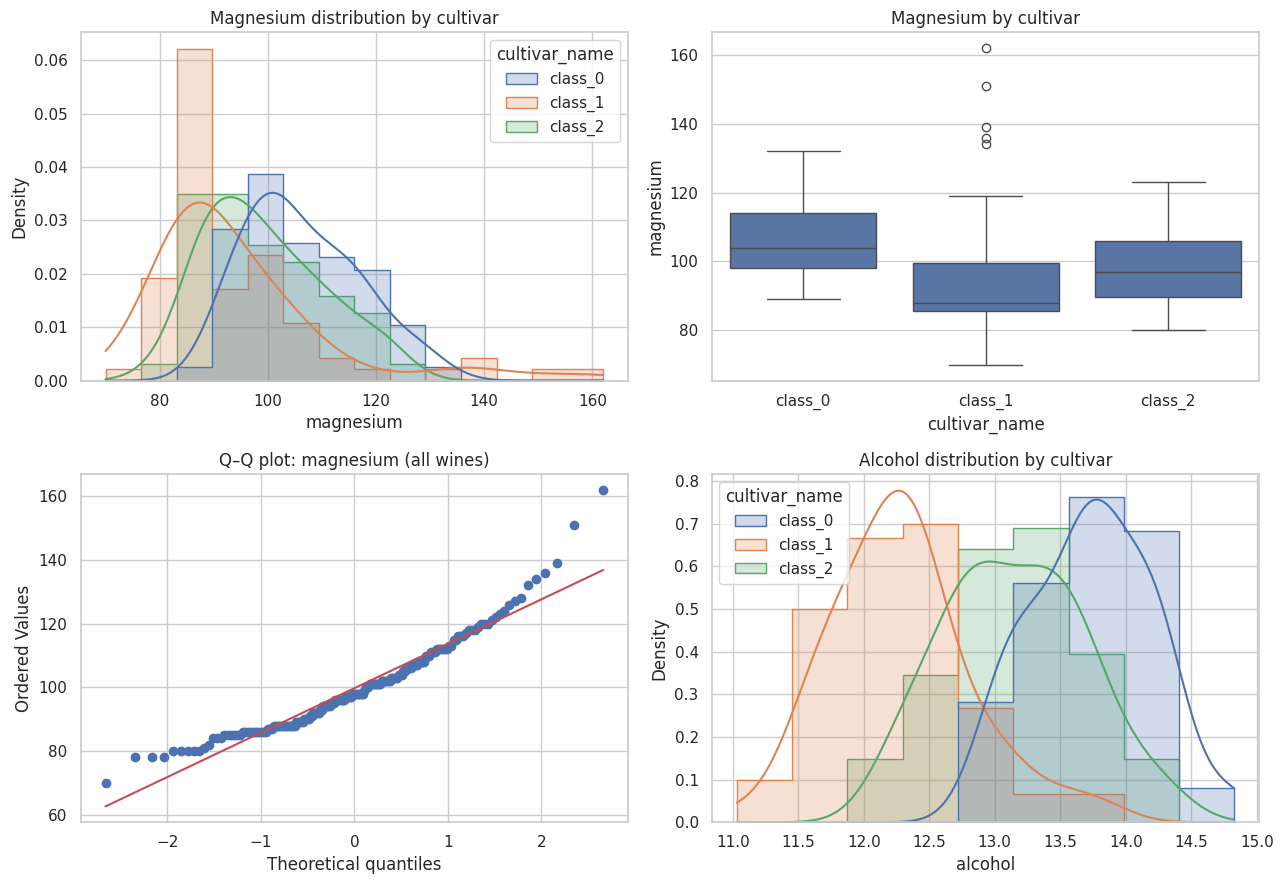

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(data=df, x="magnesium", hue="cultivar_name", kde=True, element="step",
             stat="density", common_norm=False, ax=axes[0, 0])
axes[0, 0].set_title("Magnesium distribution by cultivar")
sns.boxplot(data=df, x="cultivar_name", y="magnesium", ax=axes[0, 1])
axes[0, 1].set_title("Magnesium by cultivar")
stats.probplot(df["magnesium"], dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Q–Q plot: magnesium (all wines)")
sns.histplot(data=df, x="alcohol", hue="cultivar_name", kde=True,
             element="step", stat="density", common_norm=False, ax=axes[1, 1])
axes[1, 1].set_title("Alcohol distribution by cultivar")
plt.tight_layout()
plt.show()

In [ ]:
normality_rows = []
for cultivar, group in df.groupby("cultivar", observed=True):
    x = group["magnesium"].dropna()
    shapiro_stat, shapiro_p = stats.shapiro(x)
    z = (x - x.mean()) / x.std(ddof=1)
    ks_stat, ks_p = stats.kstest(z, "norm")
    normality_rows.append({
        "cultivar": int(cultivar),
        "n": len(x),
        "Shapiro-Wilk statistic": shapiro_stat,
        "Shapiro-Wilk p-value": shapiro_p,
        "KS statistic (standardized data)": ks_stat,
        "KS p-value (approximate)": ks_p,
        "Shapiro conclusion": "Reject normality" if shapiro_p < ALPHA else "Do not reject normality",
        "KS conclusion": "Reject normality" if ks_p < ALPHA else "Do not reject normality"
    })
normality_results = pd.DataFrame(normality_rows)
display(normality_results.round(5))

,cultivar,n,Shapiro-Wilk statistic,Shapiro-Wilk p-value,KS statistic (standardized data),KS p-value (approximate),Shapiro conclusion,KS conclusion
0,0,59,0.96486,0.08617,0.11793,0.35667,Do not reject normality,Do not reject normality
1,1,71,0.77903,0.00000,0.20137,0.00533,Reject normality,Reject normality
2,2,48,0.94963,0.03865,0.13130,0.34880,Reject normality,Do not reject normality


### How to interpret normality tests
- **H₀:** data follow a normal distribution.
- **H₁:** data do not follow a normal distribution.
- If `p < 0.05`, reject H₀; if `p ≥ 0.05`, there is insufficient evidence to reject H₀ (this does **not** prove normality).
- The KS results above are approximate because the mean and standard deviation were estimated from the same observations.

## 4. Independent two-sample tests: cultivar 0 vs cultivar 1

The Welch t-test compares means without assuming equal population variances. Mann–Whitney U is a non-parametric comparison of ranks/distributions; it is not strictly a test of medians unless distribution shapes are similar. A 95% Welch confidence interval for the difference in means is reported.

In [ ]:
g0 = df.loc[df["cultivar"] == 0, "alcohol"].dropna()
g1 = df.loc[df["cultivar"] == 1, "alcohol"].dropna()

welch = stats.ttest_ind(g0, g1, equal_var=False)
mw = stats.mannwhitneyu(g0, g1, alternative="two-sided")

# Welch-Satterthwaite confidence interval for mean(g0) - mean(g1)
diff = g0.mean() - g1.mean()
se = np.sqrt(g0.var(ddof=1)/len(g0) + g1.var(ddof=1)/len(g1))
df_num = (g0.var(ddof=1)/len(g0) + g1.var(ddof=1)/len(g1))**2
df_den = ((g0.var(ddof=1)/len(g0))**2/(len(g0)-1) +
          (g1.var(ddof=1)/len(g1))**2/(len(g1)-1))
welch_df = df_num / df_den
crit = stats.t.ppf(1 - ALPHA/2, welch_df)
ci_low, ci_high = diff - crit*se, diff + crit*se

two_group_results = pd.DataFrame([
    {"Test": "Welch independent t-test", "Statistic": welch.statistic,
     "p-value": welch.pvalue, "Conclusion": "Significant difference" if welch.pvalue < ALPHA else "No significant difference"},
    {"Test": "Mann–Whitney U", "Statistic": mw.statistic,
     "p-value": mw.pvalue, "Conclusion": "Significant distribution/rank difference" if mw.pvalue < ALPHA else "No significant difference"}
])
display(two_group_results.round(5))
print(f"Mean alcohol, cultivar 0: {g0.mean():.3f}")
print(f"Mean alcohol, cultivar 1: {g1.mean():.3f}")
print(f"Mean difference (cultivar 0 − cultivar 1): {diff:.3f}")
print(f"95% Welch CI for mean difference: [{ci_low:.3f}, {ci_high:.3f}]")

,Test,Statistic,p-value,Conclusion
0,Welch independent t-test,16.71134,0.0,Significant difference
1,Mann–Whitney U,4079.50000,0.0,Significant distribution/rank difference


Mean alcohol, cultivar 0: 13.745
Mean alcohol, cultivar 1: 12.279
Mean difference (cultivar 0 − cultivar 1): 1.466
95% Welch CI for mean difference: [1.292, 1.640]


### Hypotheses and conclusion rule
- **Welch t-test:** H₀: mean alcohol content is equal in cultivar 0 and cultivar 1. H₁: the means differ.
- **Mann–Whitney U:** H₀: the two groups have the same distribution/rank behavior. H₁: the distributions differ.
- Reject the relevant H₀ when `p < 0.05`. The confidence interval is for the mean difference (cultivar 0 minus cultivar 1); if it excludes zero, it agrees with a two-sided 5% test under the same model.

## 5. One-Way ANOVA: magnesium across three cultivars

One-Way ANOVA tests whether at least one cultivar has a different population mean magnesium level. Tukey HSD identifies which pairs differ while controlling the family-wise error rate for the pairwise comparisons.

In [ ]:
groups = [g["magnesium"].dropna().to_numpy()
          for _, g in df.groupby("cultivar", observed=True)]
oneway = stats.f_oneway(*groups)
print(f"One-Way ANOVA: F = {oneway.statistic:.4f}, p = {oneway.pvalue:.6g}")
print("Decision:", "Reject H0: at least one mean differs" if oneway.pvalue < ALPHA
      else "Do not reject H0: insufficient evidence of a mean difference")

tukey_oneway = pairwise_tukeyhsd(endog=df["magnesium"],
                                 groups=df["cultivar_name"], alpha=ALPHA)
print(tukey_oneway)

One-Way ANOVA: F = 12.4296, p = 8.9634e-06
Decision: Reject H0: at least one mean differs
  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2 meandiff p-adj   lower    upper  reject
-------------------------------------------------------
class_0 class_1 -11.7897    0.0 -17.3868 -6.1926   True
class_0 class_2  -7.0265 0.0213 -13.2022 -0.8507   True
class_1 class_2   4.7632 0.1427  -1.1738 10.7002  False
-------------------------------------------------------


### One-Way ANOVA hypotheses
- **H₀:** mean magnesium is equal across all three cultivars.
- **H₁:** at least one cultivar mean differs.
- **Assumptions:** independent observations, approximately normal residuals within groups, and similar variances. If variance homogeneity is doubtful, consider Welch ANOVA; if distributional assumptions are strongly violated, consider Kruskal–Wallis with an appropriate post-hoc test.

## 6. Two-Way ANOVA: cultivar × alcohol group

To demonstrate a two-factor design, alcohol is divided at its sample median into `Below median` and `At/above median`. The outcome remains magnesium. The model estimates the cultivar main effect, alcohol-group main effect, and interaction. Because alcohol grouping is derived from the dataset, interpret this as an exploratory grouping—not a causal experiment.

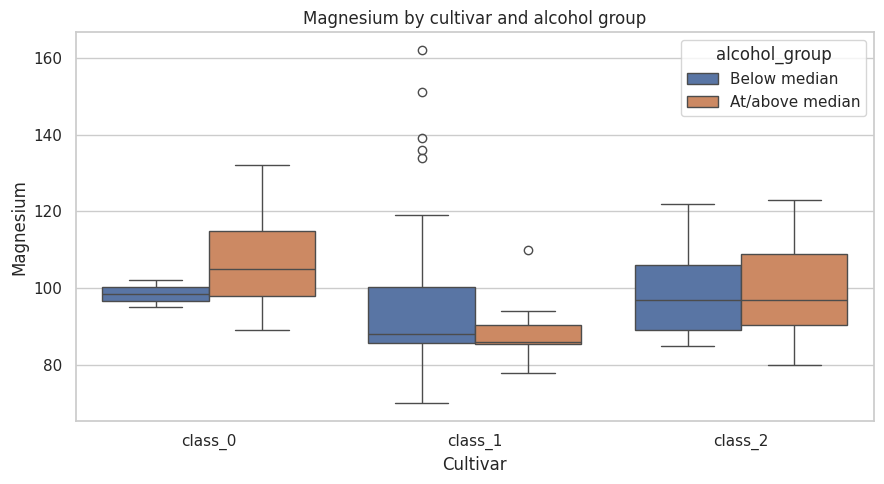

,sum_sq,df,F,PR(>F)
C(cultivar_name),2153.92398,2.0,5.92451,0.00325
C(alcohol_group),1.56631,1.0,0.00862,0.92615
C(cultivar_name):C(alcohol_group),347.22678,2.0,0.95507,0.38682
Residual,31266.31722,172.0,NaN,NaN



Residual diagnostics:
Shapiro-Wilk residual test: ShapiroResult(statistic=np.float64(0.8775164411622707), pvalue=np.float64(7.086220508678546e-11))
Levene test across cultivar × alcohol groups: LeveneResult(statistic=np.float64(0.6865407061641), pvalue=np.float64(0.6342495261584407))


In [ ]:
median_alcohol = df["alcohol"].median()
df["alcohol_group"] = np.where(df["alcohol"] < median_alcohol,
                               "Below median", "At/above median")
df["alcohol_group"] = pd.Categorical(
    df["alcohol_group"], categories=["Below median", "At/above median"]
)

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="cultivar_name", y="magnesium", hue="alcohol_group")
plt.title("Magnesium by cultivar and alcohol group")
plt.xlabel("Cultivar")
plt.ylabel("Magnesium")
plt.tight_layout()
plt.show()

model = ols("magnesium ~ C(cultivar_name) * C(alcohol_group)", data=df).fit()
two_way_table = sm.stats.anova_lm(model, typ=2)
display(two_way_table.round(5))

print("\nResidual diagnostics:")
resid = model.resid
print("Shapiro-Wilk residual test:", stats.shapiro(resid))
print("Levene test across cultivar × alcohol groups:",
      stats.levene(*[
          cell["magnesium"].to_numpy()
          for _, cell in df.groupby(["cultivar_name", "alcohol_group"], observed=True)
          if len(cell) > 0
      ]))

### Two-Way ANOVA hypotheses
For each model term, the null hypothesis is that the term contributes no effect after accounting for the other terms:
- **Cultivar:** H₀: adjusted mean magnesium does not differ by cultivar.
- **Alcohol group:** H₀: adjusted mean magnesium does not differ between the two alcohol groups.
- **Interaction:** H₀: the cultivar difference does not depend on alcohol group.

Use the p-values in the ANOVA table to assess each term at α = 0.05. A significant interaction means the association between one factor and magnesium varies across levels of the other factor; interpret main effects carefully when the interaction is significant.

## 7. Confidence intervals for group means

The following table gives 95% t-based confidence intervals for each cultivar's mean magnesium. These are individual intervals, not simultaneous family-wise intervals.

In [ ]:
ci_rows = []
for cultivar, group in df.groupby("cultivar_name", observed=True):
    x = group["magnesium"].dropna()
    mean = x.mean()
    se = stats.sem(x)
    low, high = stats.t.interval(0.95, df=len(x)-1, loc=mean, scale=se)
    ci_rows.append({"Cultivar": cultivar, "n": len(x), "Mean magnesium": mean,
                    "95% CI lower": low, "95% CI upper": high})
mean_ci = pd.DataFrame(ci_rows)
display(mean_ci.round(3))

,Cultivar,n,Mean magnesium,95% CI lower,95% CI upper
0,class_0,59,106.339,103.603,109.075
1,class_1,71,94.549,90.584,98.515
2,class_2,48,99.312,96.150,102.475


## 8. Automated findings summary

This section summarizes the decisions from the tests actually run above. Statistical tests do not replace checking assumptions, effect sizes, study design, or domain knowledge.

In [ ]:
print("STATISTICAL FINDINGS SUMMARY")
print("=" * 32)
print(f"Normality: Shapiro-Wilk rejected normality for "
      f"{(normality_results['Shapiro-Wilk p-value'] < ALPHA).sum()} of "
      f"{len(normality_results)} cultivar-specific magnesium samples.")
print(f"Welch t-test p-value: {welch.pvalue:.6g} — "
      f"{'statistically significant' if welch.pvalue < ALPHA else 'not statistically significant'}.")
print(f"Mann–Whitney U p-value: {mw.pvalue:.6g} — "
      f"{'statistically significant' if mw.pvalue < ALPHA else 'not statistically significant'}.")
print(f"One-Way ANOVA p-value: {oneway.pvalue:.6g} — "
      f"{'at least one cultivar mean differs' if oneway.pvalue < ALPHA else 'insufficient evidence of different means'}.")
for term in two_way_table.index:
    p = two_way_table.loc[term, "PR(>F)"]
    print(f"Two-Way ANOVA — {term}: p={p:.6g}; "
          f"{'significant' if p < ALPHA else 'not significant'}.")

print("\nReporting note: report exact p-values (not only 'significant'), confidence intervals, group sample sizes, and effect sizes in any formal report.")

STATISTICAL FINDINGS SUMMARY
Normality: Shapiro-Wilk rejected normality for 2 of 3 cultivar-specific magnesium samples.
Welch t-test p-value: 5.92641e-34 — statistically significant.
Mann–Whitney U p-value: 1.66978e-20 — statistically significant.
One-Way ANOVA p-value: 8.9634e-06 — at least one cultivar mean differs.
Two-Way ANOVA — C(cultivar_name): p=0.00324919; significant.
Two-Way ANOVA — C(alcohol_group): p=0.926151; not significant.
Two-Way ANOVA — C(cultivar_name):C(alcohol_group): p=0.386816; not significant.
Two-Way ANOVA — Residual: p=nan; not significant.

Reporting note: report exact p-values (not only 'significant'), confidence intervals, group sample sizes, and effect sizes in any formal report.


## 9. Limitations and reproducibility

- This notebook uses a built-in, real-world multivariate wine dataset and does not download data at runtime.
- The dataset is observational; findings describe associations in these samples and do not prove causation.
- The KS normality test is approximate when distribution parameters are estimated from the same sample.
- One-Way and Two-Way ANOVA rely on independence, residual normality, and variance assumptions. Inspect the plots and diagnostics and consider robust alternatives if assumptions are seriously violated.
- Tukey HSD is included after One-Way ANOVA. If post-hoc comparisons are needed for a specific two-way interaction, use estimated marginal means/simple-effects comparisons with multiplicity correction.
- For a business or scientific decision, include effect sizes and domain-specific practical significance, not p-values alone.

### Suggested submission checklist
- [x] Dataset loading and descriptive statistics
- [x] Histograms, box plots, and Q–Q plot
- [x] Shapiro–Wilk and Kolmogorov–Smirnov tests
- [x] Welch two-sample t-test and Mann–Whitney U test
- [x] One-Way ANOVA and Tukey HSD
- [x] Two-Way ANOVA with interaction
- [x] Null/alternative hypotheses and 95% confidence intervals
- [x] Findings summary and limitations